### Experiment notes — 1

Inspect and engineer input features. Implementation details for the methods in this notebook.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 2

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 3

Project goals and evaluation criteria. Dataset provenance, format and train/test split. Key techniques: GaussianNB.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

### Experiment notes — 4

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [4]:
import os, gc, re, base64, quopri, email
import numpy as np
import pandas as pd
from email.policy import default
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report, confusion_matrix
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer # take text feature vector
from sklearn.feature_extraction import DictVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB, ComplementNB, GaussianNB # four ，p(x|y)
from scipy.sparse import hstack

# ==================== ====================
RANDOM_STATE = 42         # data （， ratio ， 0.3
SAMPLE_RATIO = 1.0        # 1.0 table use all data
TEST_SIZE = 0.2           # test set ratio

ROOT_DIR = "trec06c-utf8"  # dataset directory
DATA_CUT_DIR = os.path.join(ROOT_DIR, "data_cut")   # tokenization email directory
LABEL_FILE = os.path.join(ROOT_DIR, "label", "index")  # label file

# testing mode
MODES = ['body', 'full', 'full_header_fields']

# text vector （ body and full mode
TEXT_VECTORIZERS = {
    'CountVectorizer': CountVectorizer(lowercase=True, token_pattern=r'(?u)\b\w+\b', ngram_range=(1,2)),
    'TfidfVectorizer': TfidfVectorizer(lowercase=True, token_pattern=r'(?u)\b\w+\b', ngram_range=(1,2))
}

# four model
NB_MODELS = {
    'MultinomialNB': MultinomialNB(),
    'BernoulliNB': BernoulliNB(),
    'ComplementNB': ComplementNB(),
    'GaussianNB': GaussianNB()
}

# text vector feature count
FEATURE_SIZES = [10, 15, 20, 50, 100, 500, 1000, 2000, 5000, 10000, 20000]

### Experiment notes — 6

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [5]:
def parse_email_header(header_text):
    """将邮件头文本解析为字典（仅头部字段）"""
    msg = email.message_from_string(header_text, policy=default)
    return dict(msg.items())

def extract_features(header_dict):
    """从邮件头字典中提取数值特征（用于 full_header_fields 模式）"""
    features = {}
    
    # 1. Received feature
    received = header_dict.get('Received', '')
    # only one Received
    features['received_count'] = len(received.split('\n')) if received else 0
    # hp-*
    features['is_dynamic_host'] = 1 if re.search(r'from\s+[\w-]+-\w+', received) else 0
    
    # 2. From and Reply-To one
    from_addr = header_dict.get('From', '')
    reply_to = header_dict.get('Reply-To', '')
    # Reply-To and From different
    features['reply_to_mismatch'] = 1 if reply_to and reply_to != from_addr else 0
    
    # 3. X-Mailer
    x_mailer = header_dict.get('X-Mailer', '')
    features['x_mailer_missing'] = 1 if not x_mailer else 0
    # for low （ < 6.00
    if x_mailer:
        version_match = re.search(r'(\d+\.\d+)', x_mailer)
        if version_match:
            features['x_mailer_version'] = float(version_match.group(1))
        else:
            features['x_mailer_version'] = 0
    else:
        features['x_mailer_version'] = 0
    
    # 4. feature
    x_priority = header_dict.get('X-Priority', '')
    features['x_priority_high'] = 1 if x_priority in ('1', '2') else 0
    features['x_msmail_priority_missing'] = 1 if 'X-MSMail-Priority' not in header_dict else 0
    
    # 5. MIME feature
    content_type = header_dict.get('Content-Type', '')
    features['has_multipart'] = 1 if 'multipart/' in content_type else 0
    features['has_content_transfer_encoding'] = 1 if 'Content-Transfer-Encoding' in header_dict else 0
    features['missing_mime_version'] = 1 if 'MIME-Version' not in header_dict else 0
    
    # 6. topic feature
    subject = header_dict.get('Subject', '')
    features['subject_length'] = len(subject)
    
    return features

### Experiment notes — 8

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*

In [6]:
# ==================== 1. load label and email path ====================
def build_email_path(rel_path):
    """将标签中的相对路径转换为 data_cut 下的实际路径"""
    # remove '../'， 'data/' for 'data_cut/'
    rel_path = rel_path.lstrip('.')
    if rel_path.startswith('/'):
        rel_path = rel_path[1:]
    rel_path = rel_path.replace('data/', 'data_cut/', 1)
    return os.path.join(ROOT_DIR, rel_path)

print("正在读取标签并构建邮件路径...")
email_data = []
with open(LABEL_FILE, 'r', encoding='utf-8', errors='ignore') as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        parts = line.split()
        if len(parts) != 2:
            continue
        label, rel_path = parts
        label = 1 if label.lower() == 'spam' else 0
        full_path = build_email_path(rel_path)
        if os.path.exists(full_path):
            email_data.append((full_path, label))
        else:
            print(f"警告：文件不存在 {full_path}，跳过")

print(f"共读取 {len(email_data)} 封邮件")

if len(email_data) == 0:
    print("未找到任何邮件文件，请检查路径配置。")
    exit()

# Implementation note
if SAMPLE_RATIO < 1.0:
    np.random.seed(RANDOM_STATE)
    sample_size = int(len(email_data) * SAMPLE_RATIO)
    indices = np.random.choice(len(email_data), sample_size, replace=False)
    email_data = [email_data[i] for i in indices]
    print(f"采样后剩余 {len(email_data)} 封邮件")
else:
    print(f"未进行邮件采样")

正在读取标签并构建邮件路径...
共读取 64620 封邮件
未进行邮件采样


In [7]:
# ==================== 2. take email （/ body ） ====================
def read_email_content(file_path, mode='body'):
    """根据 mode 返回邮件内容（文本或特征矩阵）"""
    # attempt encoding load file
    content = None
    for enc in ['gbk', 'utf-8', 'gb2312', 'gb18030']:
        try:
            with open(file_path, 'r', encoding=enc, errors='ignore') as f:
                content = f.read()
            if content.strip():
                break
        except:
            continue
    if content is None or not content.strip():
        if mode == 'body':
            return "__EMPTY_BODY__"
        elif mode == 'full':
            return ""
        else:  # full_header_fields
            return (None, None)

    lines = content.splitlines()
    header_end_idx = -1
    for i, line in enumerate(lines):
        if line.strip() == '':
            header_end_idx = i
            break

    if mode == 'body':
        if header_end_idx == -1:
            return content
        body = '\n'.join(lines[header_end_idx+1:]).strip()
        return body if body else "__EMPTY_BODY__"
    
    elif mode == 'full':
        return content
    
    elif mode == 'full_header_fields':
        # header and body
        # take header
        if header_end_idx == -1:
            header_part = content
            body = ""
        else:
            header_part = '\n'.join(lines[:header_end_idx])
            body = '\n'.join(lines[header_end_idx+1:]).strip()
        # header take feature
        header_dict = parse_email_header(header_part)
        feature_dict = extract_features(header_dict)
        # body （ body for ， vector retain
        body_text = body if body else "__EMPTY_BODY__"
        return (feature_dict, body_text)
    else:
        raise ValueError(f"未知模式: {mode}")

### Experiment notes — 11

Review the implementation and results for this stage of the experiment.

*English presentation summary; the complete original narrative is preserved in `archive/original_notebook.ipynb`.*


开始处理模式: body
处理第 0 封邮件
处理第 1000 封邮件
处理第 2000 封邮件
处理第 3000 封邮件
处理第 4000 封邮件
处理第 5000 封邮件
处理第 6000 封邮件
处理第 7000 封邮件
处理第 8000 封邮件
处理第 9000 封邮件
处理第 10000 封邮件
处理第 11000 封邮件
处理第 12000 封邮件
处理第 13000 封邮件
处理第 14000 封邮件
处理第 15000 封邮件
处理第 16000 封邮件
处理第 17000 封邮件
处理第 18000 封邮件
处理第 19000 封邮件
处理第 20000 封邮件
处理第 21000 封邮件
处理第 22000 封邮件
处理第 23000 封邮件
处理第 24000 封邮件
处理第 25000 封邮件
处理第 26000 封邮件
处理第 27000 封邮件
处理第 28000 封邮件
处理第 29000 封邮件
处理第 30000 封邮件
处理第 31000 封邮件
处理第 32000 封邮件
处理第 33000 封邮件
处理第 34000 封邮件
处理第 35000 封邮件
处理第 36000 封邮件
处理第 37000 封邮件
处理第 38000 封邮件
处理第 39000 封邮件
处理第 40000 封邮件
处理第 41000 封邮件
处理第 42000 封邮件
处理第 43000 封邮件
处理第 44000 封邮件
处理第 45000 封邮件
处理第 46000 封邮件
处理第 47000 封邮件
处理第 48000 封邮件
处理第 49000 封邮件
处理第 50000 封邮件
处理第 51000 封邮件
处理第 52000 封邮件
处理第 53000 封邮件
处理第 54000 封邮件
处理第 55000 封邮件
处理第 56000 封邮件
处理第 57000 封邮件
处理第 58000 封邮件
处理第 59000 封邮件
处理第 60000 封邮件
处理第 61000 封邮件
处理第 62000 封邮件
处理第 63000 封邮件
处理第 64000 封邮件
成功提取内容的邮件数: 64620，其中空邮件数: 357
训练集: 51696, 测试集: 12924

  特征数 = 10
    训练 CountVectorizer +

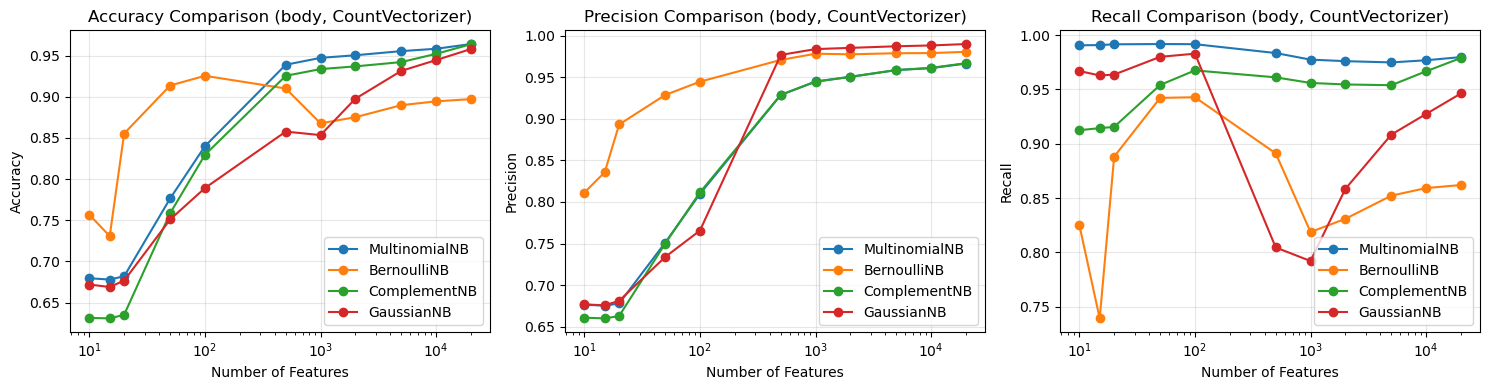

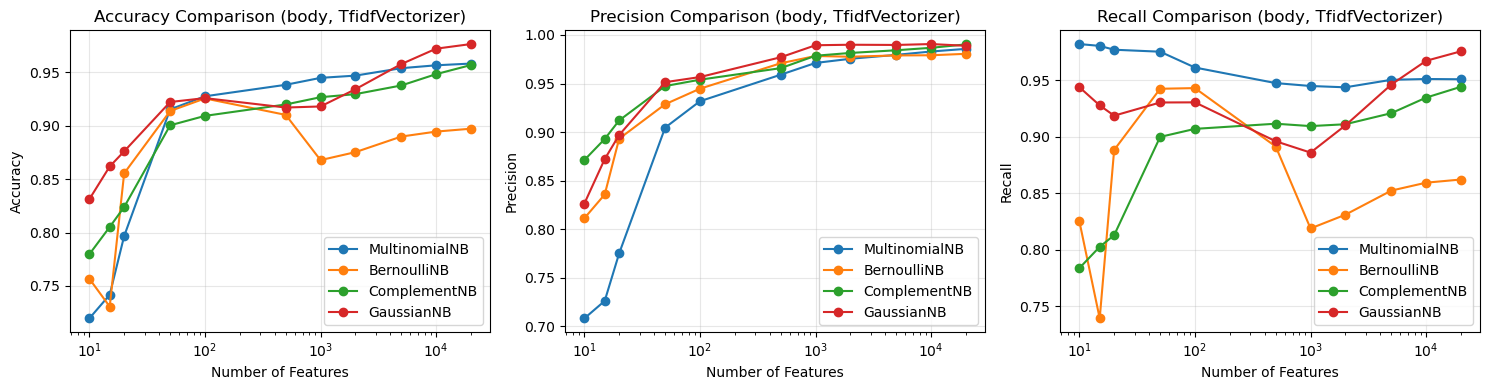


  模式 body 最佳组合：TfidfVectorizer + GaussianNB @ 20000 特征，综合得分 0.9802
    准确率: 0.9764, 精确率: 0.9889, 召回率: 0.9754

开始处理模式: full
处理第 0 封邮件
处理第 1000 封邮件
处理第 2000 封邮件
处理第 3000 封邮件
处理第 4000 封邮件
处理第 5000 封邮件
处理第 6000 封邮件
处理第 7000 封邮件
处理第 8000 封邮件
处理第 9000 封邮件
处理第 10000 封邮件
处理第 11000 封邮件
处理第 12000 封邮件
处理第 13000 封邮件
处理第 14000 封邮件
处理第 15000 封邮件
处理第 16000 封邮件
处理第 17000 封邮件
处理第 18000 封邮件
处理第 19000 封邮件
处理第 20000 封邮件
处理第 21000 封邮件
处理第 22000 封邮件
处理第 23000 封邮件
处理第 24000 封邮件
处理第 25000 封邮件
处理第 26000 封邮件
处理第 27000 封邮件
处理第 28000 封邮件
处理第 29000 封邮件
处理第 30000 封邮件
处理第 31000 封邮件
处理第 32000 封邮件
处理第 33000 封邮件
处理第 34000 封邮件
处理第 35000 封邮件
处理第 36000 封邮件
处理第 37000 封邮件
处理第 38000 封邮件
处理第 39000 封邮件
处理第 40000 封邮件
处理第 41000 封邮件
处理第 42000 封邮件
处理第 43000 封邮件
处理第 44000 封邮件
处理第 45000 封邮件
处理第 46000 封邮件
处理第 47000 封邮件
处理第 48000 封邮件
处理第 49000 封邮件
处理第 50000 封邮件
处理第 51000 封邮件
处理第 52000 封邮件
处理第 53000 封邮件
处理第 54000 封邮件
处理第 55000 封邮件
处理第 56000 封邮件
处理第 57000 封邮件
处理第 58000 封邮件
处理第 59000 封邮件
处理第 60000 封邮件
处理第 61000 封邮件
处理第 62000 封邮件
处理第 630

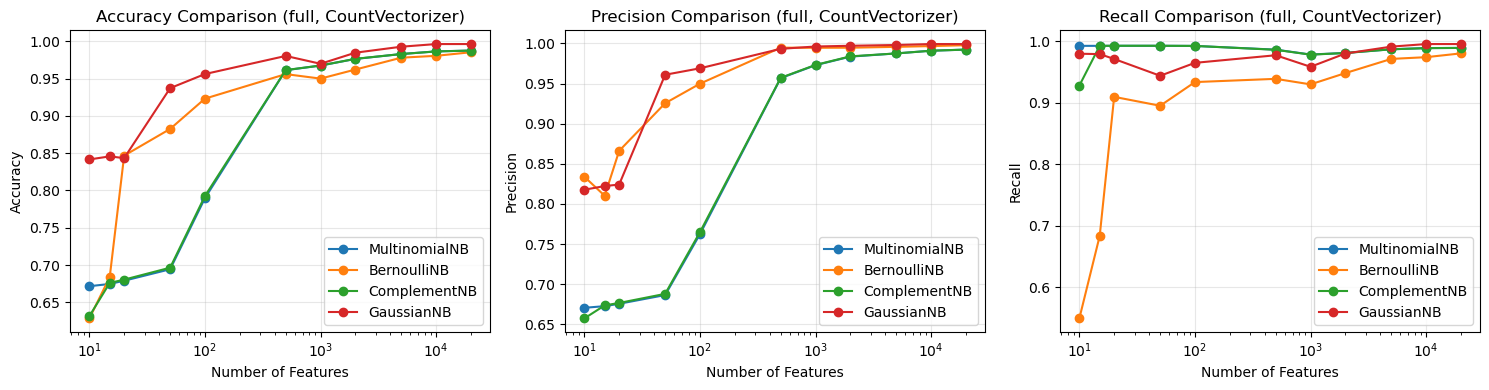

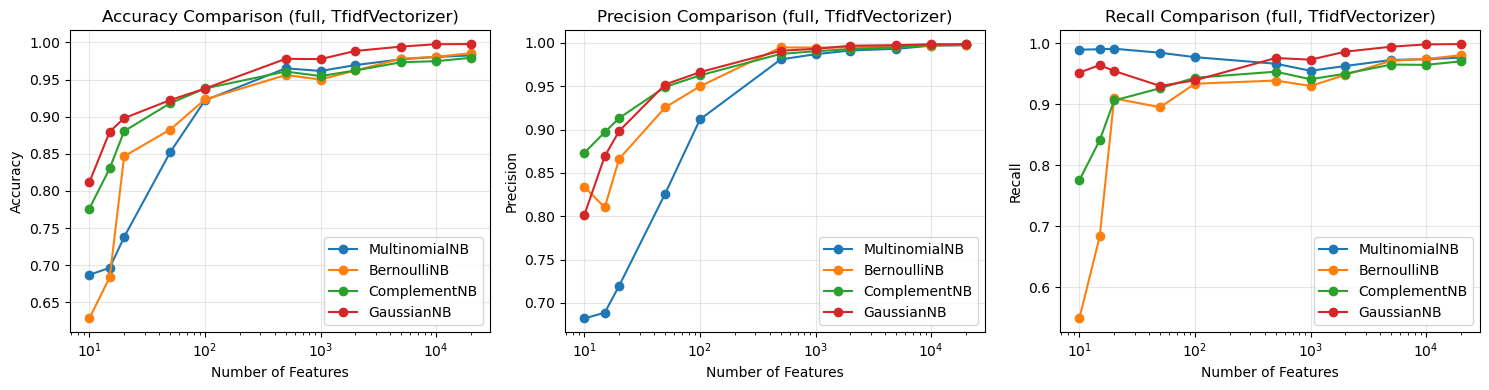


  模式 full 最佳组合：TfidfVectorizer + GaussianNB @ 20000 特征，综合得分 0.9981
    准确率: 0.9978, 精确率: 0.9983, 召回率: 0.9984

开始处理模式: full_header_fields
处理第 0 封邮件
处理第 1000 封邮件
处理第 2000 封邮件
处理第 3000 封邮件
处理第 4000 封邮件
处理第 5000 封邮件
处理第 6000 封邮件
处理第 7000 封邮件
处理第 8000 封邮件
处理第 9000 封邮件
处理第 10000 封邮件
处理第 11000 封邮件
处理第 12000 封邮件
处理第 13000 封邮件
处理第 14000 封邮件
处理第 15000 封邮件
处理第 16000 封邮件
处理第 17000 封邮件
处理第 18000 封邮件
处理第 19000 封邮件
处理第 20000 封邮件
处理第 21000 封邮件
处理第 22000 封邮件
处理第 23000 封邮件
处理第 24000 封邮件
处理第 25000 封邮件
处理第 26000 封邮件
处理第 27000 封邮件
处理第 28000 封邮件
处理第 29000 封邮件
处理第 30000 封邮件
处理第 31000 封邮件
处理第 32000 封邮件
处理第 33000 封邮件
处理第 34000 封邮件
处理第 35000 封邮件
处理第 36000 封邮件
处理第 37000 封邮件
处理第 38000 封邮件
处理第 39000 封邮件
处理第 40000 封邮件
处理第 41000 封邮件
处理第 42000 封邮件
处理第 43000 封邮件
处理第 44000 封邮件
处理第 45000 封邮件
处理第 46000 封邮件
处理第 47000 封邮件
处理第 48000 封邮件
处理第 49000 封邮件
处理第 50000 封邮件
处理第 51000 封邮件
处理第 52000 封邮件
处理第 53000 封邮件
处理第 54000 封邮件
处理第 55000 封邮件
处理第 56000 封邮件
处理第 57000 封邮件
处理第 58000 封邮件
处理第 59000 封邮件
处理第 60000 封邮件
处理第 61000 封邮件
处理第 620

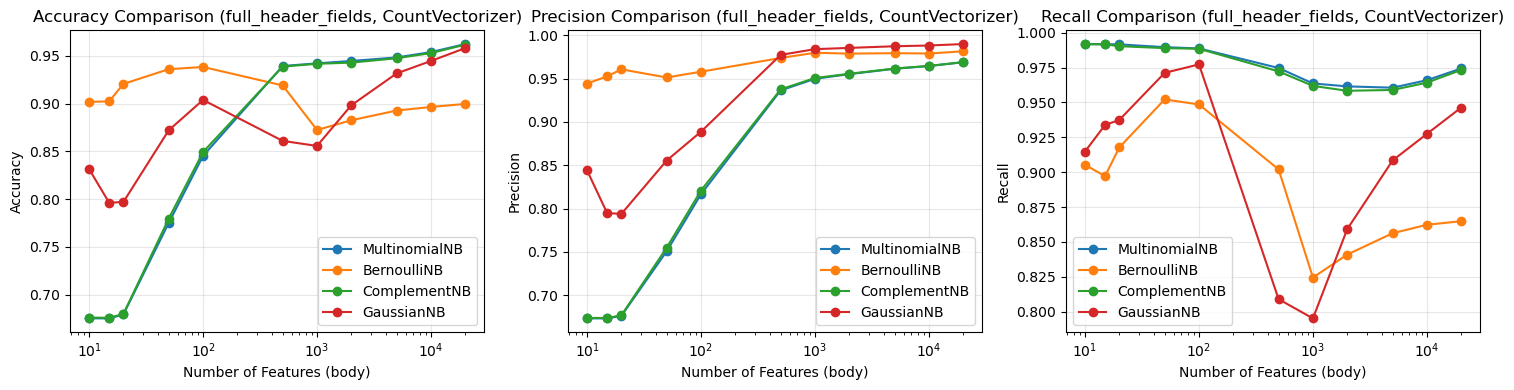

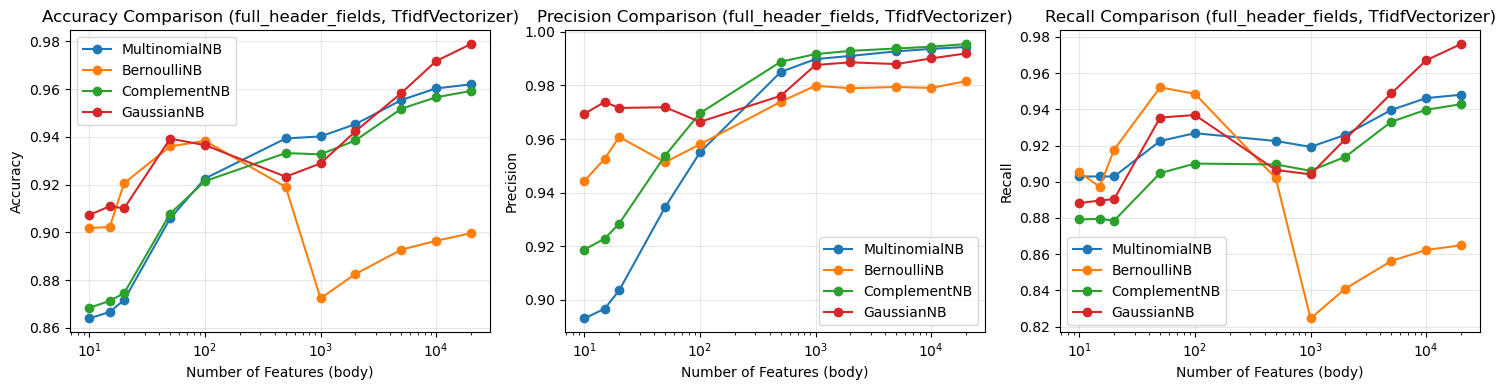


  模式 full_header_fields 最佳组合：TfidfVectorizer + GaussianNB @ 20000 特征，综合得分 0.9823
    准确率: 0.9789, 精确率: 0.9919, 召回率: 0.9761


In [8]:
# ==================== 3. experiment validation ： different mode X different probability compute method ====================
results_summary = {}  # each mode best results

for mode in MODES:
    print(f"\n{'='*50}")
    print(f"开始处理模式: {mode}")
    print('='*50)

    if mode in ['body', 'full']:
        # text mode ： text
        X_data = []
        y_data = []
        empty_count = 0
        for i, (path, label) in enumerate(email_data):
            if i % 1000 == 0:
                print(f"处理第 {i} 封邮件")
            text = read_email_content(path, mode=mode)
            if text is not None:
                if mode == 'body' and text == "__EMPTY_BODY__":
                    empty_count += 1
                X_data.append(text)
                y_data.append(label)
            else:
                print(f"警告：{path} 无法读取内容，已跳过")
        print(f"成功提取内容的邮件数: {len(X_data)}，其中空邮件数: {empty_count}")
        if len(X_data) == 0:
            print("该模式无有效邮件，跳过")
            continue

        # split training / test set
        X_train, X_test, y_train, y_test = train_test_split(
            X_data, y_data, test_size=TEST_SIZE,
            random_state=RANDOM_STATE, stratify=y_data
        )
        print(f"训练集: {len(X_train)}, 测试集: {len(X_test)}")

        # mode results
        results = {
            vec_name: {
                model_name: {
                    'max_features': [],
                    'accuracy': [],
                    'precision': [],
                    'recall': []
                } for model_name in NB_MODELS
            } for vec_name in TEXT_VECTORIZERS
        }

        for n_features in FEATURE_SIZES:
            print(f"\n  特征数 = {n_features}")
            for vec_name, vectorizer in TEXT_VECTORIZERS.items():
                vectorizer.set_params(max_features=n_features)
                X_train_vec = vectorizer.fit_transform(X_train)
                X_test_vec = vectorizer.transform(X_test)

                for clf_name, clf in NB_MODELS.items():
                    print(f"    训练 {vec_name} + {clf_name}...")
                    if clf_name == 'GaussianNB':
                        X_train_dense = X_train_vec.toarray()
                        X_test_dense = X_test_vec.toarray()
                        clf.fit(X_train_dense, y_train)
                        y_pred = clf.predict(X_test_dense)
                    else:
                        clf.fit(X_train_vec, y_train)
                        y_pred = clf.predict(X_test_vec)

                    acc = accuracy_score(y_test, y_pred)
                    prec = precision_score(y_test, y_pred, zero_division=0)
                    rec = recall_score(y_test, y_pred, zero_division=0)

                    results[vec_name][clf_name]['max_features'].append(n_features)
                    results[vec_name][clf_name]['accuracy'].append(acc)
                    results[vec_name][clf_name]['precision'].append(prec)
                    results[vec_name][clf_name]['recall'].append(rec)

                    print(f"      Acc={acc:.4f}, Prec={prec:.4f}, Rec={rec:.4f}")

                del X_train_vec, X_test_vec
                gc.collect()

        # plot performance plot （， and
        for vec_name in TEXT_VECTORIZERS:
            plt.figure(figsize=(15, 4))
            for idx, metric in enumerate(['accuracy', 'precision', 'recall']):
                plt.subplot(1, 3, idx+1)
                for model_name in NB_MODELS:
                    plt.plot(results[vec_name][model_name]['max_features'],
                             results[vec_name][model_name][metric],
                             marker='o', label=model_name)
                plt.xscale('log')
                plt.xlabel('Number of Features')
                plt.ylabel(metric.capitalize())
                plt.title(f'{metric.capitalize()} Comparison ({mode}, {vec_name})')
                plt.legend()
                plt.grid(True, alpha=0.3)
            plt.tight_layout()
            # plt.savefig(f'performance_{mode}_{vec_name}.png', dpi=150)
            plt.show()

        # best
        best_score = -1
        best_vec = None
        best_model = None
        best_n = None
        best_metrics = {}
        for vec_name in TEXT_VECTORIZERS:
            for model_name in NB_MODELS:
                for i, n in enumerate(results[vec_name][model_name]['max_features']):
                    acc = results[vec_name][model_name]['accuracy'][i]
                    prec = results[vec_name][model_name]['precision'][i]
                    rec = results[vec_name][model_name]['recall'][i]
                    score = (acc + prec + rec) / 3
                    if score > best_score:
                        best_score = score
                        best_vec = vec_name
                        best_model = model_name
                        best_n = n
                        best_metrics = {'accuracy': acc, 'precision': prec, 'recall': rec}

        print(f"\n  模式 {mode} 最佳组合：{best_vec} + {best_model} @ {best_n} 特征，综合得分 {best_score:.4f}")
        print(f"    准确率: {best_metrics['accuracy']:.4f}, 精确率: {best_metrics['precision']:.4f}, 召回率: {best_metrics['recall']:.4f}")

        results_summary[mode] = {
            'type': 'text',
            'best_vectorizer': best_vec,
            'best_model': best_model,
            'best_n_features': best_n,
            'metrics': best_metrics,
            'full_results': results
        }

    else:  # full_header_fields mode （ feature engineering
        # header feature and body text
        header_dicts = []
        body_texts = []
        y_data = []
        empty_count = 0
        for i, (path, label) in enumerate(email_data):
            if i % 1000 == 0:
                print(f"处理第 {i} 封邮件")
            ret = read_email_content(path, mode=mode)
            if ret[0] is not None and ret[1] is not None:
                feature_dict, body = ret
                header_dicts.append(feature_dict)
                body_texts.append(body)
                y_data.append(label)
                if body == "__EMPTY_BODY__":
                    empty_count += 1
            else:
                print(f"警告：{path} 无法读取内容，已跳过")
        print(f"成功提取内容的邮件数: {len(header_dicts)}，其中空邮件数: {empty_count}")
        if len(header_dicts) == 0:
            print("该模式无有效邮件，跳过")
            continue

        # split training / test set （ one split
        X_train_dict, X_test_dict, y_train, y_test = train_test_split(
            header_dicts, y_data, test_size=TEST_SIZE,
            random_state=RANDOM_STATE, stratify=y_data
        )
        # split body text
        # one ， header_dicts and body_texts
        # use train_test_split table
        X_train_dict, X_test_dict, y_train, y_test, X_train_body, X_test_body = train_test_split(
            header_dicts, y_data, body_texts, test_size=TEST_SIZE,
            random_state=RANDOM_STATE, stratify=y_data
        )
        print(f"训练集: {len(X_train_dict)}, 测试集: {len(X_test_dict)}")

        # header feature convert for feature matrix （DictVectorizer
        dict_vec = DictVectorizer()
        X_train_header = dict_vec.fit_transform(X_train_dict)
        X_test_header = dict_vec.transform(X_test_dict)
        # header feature dimensions
        header_dim = X_train_header.shape[1]
        print(f"头部特征维度: {header_dim}")

        # mode results
        results = {
            vec_name: {
                model_name: {
                    'max_features': [],
                    'accuracy': [],
                    'precision': [],
                    'recall': []
                } for model_name in NB_MODELS
            } for vec_name in TEXT_VECTORIZERS
        }

        for n_features in FEATURE_SIZES:
            print(f"\n  特征数 = {n_features}")
            for vec_name, vectorizer in TEXT_VECTORIZERS.items():
                # body vector
                vectorizer.set_params(max_features=n_features)
                X_train_body_vec = vectorizer.fit_transform(X_train_body)
                X_test_body_vec = vectorizer.transform(X_test_body)

                # merge header feature and body feature （ sparse matrix concatenate
                X_train_merged = hstack([X_train_header, X_train_body_vec])
                X_test_merged = hstack([X_test_header, X_test_body_vec])

                for clf_name, clf in NB_MODELS.items():
                    print(f"    训练 {vec_name} + {clf_name}...")
                    if clf_name == 'GaussianNB':
                        # GaussianNB， convert for matrix （ note
                        X_train_dense = X_train_merged.toarray()
                        X_test_dense = X_test_merged.toarray()
                        clf.fit(X_train_dense, y_train)
                        y_pred = clf.predict(X_test_dense)
                    else:
                        clf.fit(X_train_merged, y_train)
                        y_pred = clf.predict(X_test_merged)

                    acc = accuracy_score(y_test, y_pred)
                    prec = precision_score(y_test, y_pred, zero_division=0)
                    rec = recall_score(y_test, y_pred, zero_division=0)

                    results[vec_name][clf_name]['max_features'].append(n_features)
                    results[vec_name][clf_name]['accuracy'].append(acc)
                    results[vec_name][clf_name]['precision'].append(prec)
                    results[vec_name][clf_name]['recall'].append(rec)

                    print(f"      Acc={acc:.4f}, Prec={prec:.4f}, Rec={rec:.4f}")

                del X_train_body_vec, X_test_body_vec, X_train_merged, X_test_merged
                gc.collect()

        # plot performance plot （ and text mode
        for vec_name in TEXT_VECTORIZERS:
            plt.figure(figsize=(15, 4))
            for idx, metric in enumerate(['accuracy', 'precision', 'recall']):
                plt.subplot(1, 3, idx+1)
                for model_name in NB_MODELS:
                    plt.plot(results[vec_name][model_name]['max_features'],
                             results[vec_name][model_name][metric],
                             marker='o', label=model_name)
                plt.xscale('log')
                plt.xlabel('Number of Features (body)')
                plt.ylabel(metric.capitalize())
                plt.title(f'{metric.capitalize()} Comparison ({mode}, {vec_name})')
                plt.legend()
                plt.grid(True, alpha=0.3)
            plt.tight_layout()
            # plt.savefig(f'performance_{mode}_{vec_name}.png', dpi=150)
            plt.show()

        # best
        best_score = -1
        best_vec = None
        best_model = None
        best_n = None
        best_metrics = {}
        for vec_name in TEXT_VECTORIZERS:
            for model_name in NB_MODELS:
                for i, n in enumerate(results[vec_name][model_name]['max_features']):
                    acc = results[vec_name][model_name]['accuracy'][i]
                    prec = results[vec_name][model_name]['precision'][i]
                    rec = results[vec_name][model_name]['recall'][i]
                    score = (acc + prec + rec) / 3
                    if score > best_score:
                        best_score = score
                        best_vec = vec_name
                        best_model = model_name
                        best_n = n
                        best_metrics = {'accuracy': acc, 'precision': prec, 'recall': rec}

        print(f"\n  模式 {mode} 最佳组合：{best_vec} + {best_model} @ {best_n} 特征，综合得分 {best_score:.4f}")
        print(f"    准确率: {best_metrics['accuracy']:.4f}, 精确率: {best_metrics['precision']:.4f}, 召回率: {best_metrics['recall']:.4f}")

        results_summary[mode] = {
            'type': 'combined',
            'best_vectorizer': best_vec,
            'best_model': best_model,
            'best_n_features': best_n,
            'metrics': best_metrics,
            'full_results': results,
            'header_dim': header_dim
        }

In [9]:
# ==================== 4. output ====================
print("\n" + "="*60)
print("最终结果总结")
print("="*60)
for mode, info in results_summary.items():
    if info['type'] == 'text':
        print(f"\n模式 [{mode}]")
        print(f"  最佳组合: {info['best_vectorizer']} + {info['best_model']} @ {info['best_n_features']} 特征")
        print(f"  准确率: {info['metrics']['accuracy']:.4f}")
        print(f"  精确率: {info['metrics']['precision']:.4f}")
        print(f"  召回率: {info['metrics']['recall']:.4f}")
    else:  # combined
        print(f"\n模式 [{mode}] (头部特征 + 正文文本向量化)")
        print(f"  最佳组合: {info['best_vectorizer']} + {info['best_model']} @ {info['best_n_features']} 特征")
        print(f"  头部特征维度: {info['header_dim']}")
        print(f"  准确率: {info['metrics']['accuracy']:.4f}")
        print(f"  精确率: {info['metrics']['precision']:.4f}")
        print(f"  召回率: {info['metrics']['recall']:.4f}")


最终结果总结

模式 [body]
  最佳组合: TfidfVectorizer + GaussianNB @ 20000 特征
  准确率: 0.9764
  精确率: 0.9889
  召回率: 0.9754

模式 [full]
  最佳组合: TfidfVectorizer + GaussianNB @ 20000 特征
  准确率: 0.9978
  精确率: 0.9983
  召回率: 0.9984

模式 [full_header_fields] (头部特征 + 正文文本向量化)
  最佳组合: TfidfVectorizer + GaussianNB @ 20000 特征
  头部特征维度: 11
  准确率: 0.9789
  精确率: 0.9919
  召回率: 0.9761
